# 가드레일 실습: 상담 질문 셋에 가리기·예약·감사 기록 붙이기

**이 노트북에서 할 일**

1. 가짜 개인정보가 든 상담 질문 셋을 02절 함수로 가립니다.
2. 04절 예약과 05절 감사 기록을 붙인 조립 함수로 질문 셋을 차례로 처리합니다.
3. 호출 한도 하나만 바꿔 한 번 더 실행하고, 두 실행의 기록을 지문으로 짝지어 견줍니다.

**준비물** — 이 절은 프로젝트 맨 위 폴더의 `.env`에 적어 둔 `OPENAI_API_KEY`를 씁니다.
모델 요청은 모두 세 번이고, 실행 1에서 두 번, 실행 2에서 한 번 `gpt-5.4-mini`에 보냅니다.
임베딩 요청은 없습니다.
노트북을 한 번 실행하는 요금은 요금표로 어림해 미화 0.01달러 아래입니다.
실제 청구 금액과는 다를 수 있습니다.

읽는 파일은 이 챕터 자료 파일 `data/retrieved-documents.json` 하나이고, 읽기만 합니다.
새로 쓰는 파일은 없습니다. 감사 기록은 노트북 안 목록에만 남깁니다.
교재 출력을 만든 실행에서는 노트북 전체가 약 5초 만에 끝났습니다.

**기준 버전** — 첫 셀에서 LangChain 1.4.0과 langchain-openai 1.6.1을 설치합니다.
키를 읽는 python-dotenv 1.2.3도 함께 설치합니다.
교재 출력은 Linux의 Python 3.12.13으로 만들었습니다.
다른 판과 Windows·macOS에서는 이번에 실행하지 않았습니다.

**실습 범위** — 이 절은 챕터 끝 실습 절이고 30분 안에 끝나는 분량입니다.
강사와 함께 첫 셀부터 차례로 실행하고, 따로 내는 과제는 없습니다.
01~06절에서 쓴 이름과 문법만 씁니다.

실습 폴더 `labs/part4/ch16-guardrails`에서 `uv sync --locked`를 실행합니다.
그다음 이 폴더의 `.venv` 커널을 고르고 첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

![위에서 아래로 읽는 그림으로 초록 상자 상담 질문 셋에서 파란 상자 가리기 mask_pii 02절과 파란 상자 예약 reserve 04절을 지나고, 예약에서 왼쪽 실선은 보라 상자 모델 gpt-5.4-mini와 파란 상자 기록 한 줄 남기기 note_event answer로, 오른쪽 점선 한도를 넘으면 멈춤은 파란 상자 기록 한 줄 남기기 note_event stopped로 가며, 두 기록 상자가 맨 아래 초록 상자 기록 목록 파일에 쓰지 않음으로 모이는 그림](attachment:07-1-가리기-예약-기록의-조립.png)

위에서 아래로 읽습니다. 초록 질문 셋이 파란 가리기와 예약을 지나 왼쪽 보라 모델에 닿습니다.
오른쪽 점선은 호출 한도를 넘을 때만 가는 갈래이고, 두 기록 상자는 맨 아래 초록 기록 목록으로 모입니다.
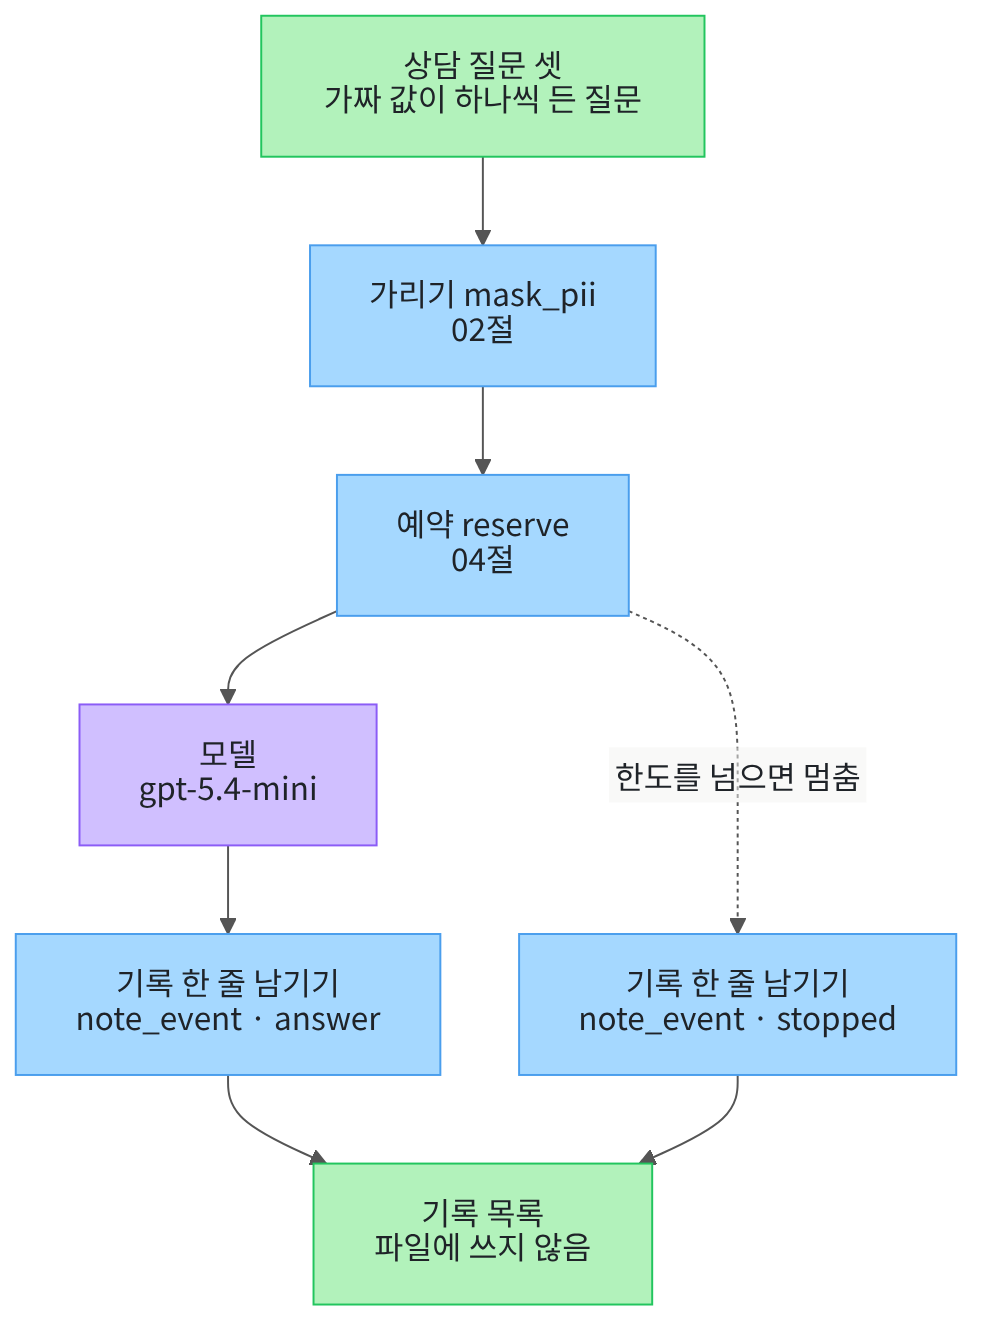

## 1. 준비

이번 절은 이 챕터의 실습입니다.
01~06절에서 쓴 이름과 문법만 쓰고 따로 내는 과제는 없습니다.
첫 셀은 패키지 세 개를 설치하고 설치된 판 번호를 출력합니다.
설치에는 몇십 초가 걸릴 수 있습니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "langchain==1.4.0" "langchain-openai==1.6.1" "python-dotenv==1.2.3"
from importlib.metadata import version

print("langchain:", version("langchain"))
print("langchain-openai:", version("langchain-openai"))
print("python-dotenv:", version("python-dotenv"))

Note: you may need to restart the kernel to use updated packages.


langchain: 1.4.0
langchain-openai: 1.6.1
python-dotenv: 1.2.3


**결과 읽기** — 설치가 끝나면 판 번호 세 줄이 보입니다.
출력 줄 `langchain: 1.4.0`과 `langchain-openai: 1.6.1`이 실습 폴더 잠금과 같은 판입니다.
이 노트북의 출력은 2026-09-23에 이 판으로 실행한 결과입니다.

다음 셀은 이 절에서 쓸 모듈과 앞 절 함수 일곱을 불러옵니다.
02절 함수 둘, 04절 함수 둘, 05절 함수 둘, 06절 함수 하나를 다시 씁니다.

앞에서 배운 함수는 `guardrails.py`에 모아 두었습니다. 파일을 열면 코드를 볼 수 있습니다. 노트북과 같은 폴더(`notebooks/`)에 있는 파일입니다. 커널이 `notebooks/` 폴더에서 시작해야 이 파일을 가져올 수 있습니다.
일곱 함수 모두 앞 절에서 쓰던 인자 그대로입니다.

In [2]:
# 자료 파일을 읽을 모듈, 앞 절 함수 일곱, 모델을 만들 이름을 불러옵니다
import json
import os

from guardrails import build_rag_messages, find_raw_values, fingerprint_of, make_budget, mask_pii, reserve, safe_detail
from langchain.chat_models import init_chat_model

print("02절:", "find_raw_values", "mask_pii")
print("04절:", "make_budget", "reserve")
print("05절:", "fingerprint_of", "safe_detail")
print("06절:", "build_rag_messages")

02절: find_raw_values mask_pii
04절: make_budget reserve
05절: fingerprint_of safe_detail
06절: build_rag_messages


**결과 읽기** — 출력 네 줄이 절마다 가져온 함수 이름입니다.
출력 줄 `02절: find_raw_values mask_pii`의 두 함수로 질문을 가리고 원문 값을 찾습니다.
출력 줄 `05절: fingerprint_of safe_detail`의 두 함수로 감사 기록 한 줄의 칸을 만듭니다.
출력 줄 `06절: build_rag_messages`는 모델에 보낼 메시지를 만드는 데만 씁니다.

## 2. 키와 모델 준비

이 절도 01~06절과 같은 모델 `gpt-5.4-mini` 하나만 씁니다.

API 키가 있는지 확인합니다. `True` 값이 나오면 다음으로 넘어갑니다.

In [3]:
# .env 파일에서 OpenAI API 키를 읽습니다(키 값은 출력하지 않습니다)
import os
from dotenv import find_dotenv, load_dotenv

env_path = find_dotenv(usecwd=True)
load_dotenv(env_path)
has_key = os.getenv("OPENAI_API_KEY") is not None
print("OPENAI_API_KEY 설정 여부:", has_key)
assert has_key, "프로젝트 폴더의 .env 파일에 OPENAI_API_KEY를 적어 주세요."

OPENAI_API_KEY 설정 여부: True


실습에 쓸 모델을 준비합니다.
temperature 값을 0으로 두어도 답 문장이 매번 같다고 보장하지는 않습니다.

In [4]:
# 실습에 쓸 모델을 준비합니다
model = init_chat_model(
    "openai:gpt-5.4-mini",
    temperature=0,
    reasoning_effort="none",
)
print("모델 이름:", model.model_name)
print("temperature:", model.temperature)

모델 이름: gpt-5.4-mini
temperature: 0.0


**결과 읽기** — 모델 이름 `gpt-5.4-mini`, temperature `0.0`이 보이면 준비가 끝났습니다.
이 노트북의 출력은 2026-09-23에 이 모델로 실행한 결과입니다.

## 3. 상황과 재료

이 실습의 상황은 이렇습니다.
미르시립도서관 상담 창구에 질문 셋이 차례로 들어왔습니다.
사용자는 질문마다 연락처나 카드 번호를 함께 적었습니다.
창구는 질문을 가린 뒤 모델에 보냅니다.
모델 요청은 정한 호출 한도 안에서만 하고, 한 일은 모두 기록합니다.

먼저 노트북을 연 자리에서 프로젝트 맨 위를 찾습니다.
01~06절과 같은 자리 찾기 셀입니다.

In [5]:
# 노트북을 어느 폴더에서 열어도 프로젝트 맨 위를 찾게 후보 세 개를 차례로 봅니다
candidates = [".", "../../..", "../../../.."]
root_path = None
for candidate in candidates:
    if os.path.exists(candidate + "/labs/part4/ch16-guardrails/data"):
        root_path = candidate
        break
print("찾은 프로젝트 맨 위:", root_path)
assert root_path is not None, "notebooks 폴더나 실습 폴더 맨 위에서 노트북을 열어 주세요."

찾은 프로젝트 맨 위: .


**결과 읽기** — 출력 줄 `찾은 프로젝트 맨 위:` 뒤에 점 하나나 위로 올라가는 자리가 보입니다.

다음 셀은 자료 파일을 읽고 안내 문서 `E01` 하나만 고릅니다.
01~05절과 같은 검색 결과입니다.
공격 문서 `E99`는 06절에서 살펴본 문서라 이 실습에서는 쓰지 않습니다.

In [6]:
# 자료 파일을 읽고 이 실습의 검색 결과로 안내 문서 E01 하나만 고릅니다(읽기만 합니다)
data_path = root_path + "/labs/part4/ch16-guardrails/data"
with open(data_path + "/retrieved-documents.json", encoding="utf-8") as file:
    all_documents = json.loads(file.read())
retrieved = []
for document in all_documents:
    if document["doc_id"] == "E01":
        retrieved.append(document)
print("자료 파일의 문서 수:", len(all_documents))
print("고른 문서:", retrieved[0]["doc_id"], "|", retrieved[0]["title"])

자료 파일의 문서 수: 2
고른 문서: E01 | 미르시립도서관 이용 안내


**결과 읽기** — 출력 줄 `자료 파일의 문서 수: 2`로 자료 파일에는 문서가 둘 있습니다.
출력 줄 `고른 문서: E01 | 미르시립도서관 이용 안내`가 이 실습의 검색 결과입니다.
세 질문 모두 이 문서 하나를 붙여 모델에 보냅니다.

다음 셀은 상담 질문 셋을 적습니다.
질문은 이 절에서 실행 전에 적은 글이고, 가짜 값 셋은 02절에서 지어낸 값입니다.
실제 사람의 정보가 아닙니다.

In [7]:
# 실행 전에 정한 상담 질문 셋입니다: 질문은 이 절에서 적었고, 가짜 값 셋은 02절에서 지어낸 값입니다
fake_values = ["test.user@example.com", "010-0000-0000", "1111-2222-3333-4444"]
questions = [
    "이번 주 월요일에 책을 반납하러 가도 되나요? 답은 " + fake_values[0] + " 으로 보내 주세요.",
    "공휴일이 월요일과 겹치면 화요일에도 쉬나요? 연락처는 " + fake_values[1] + " 입니다.",
    "법정 공휴일에도 문을 여나요? 연체료는 카드 " + fake_values[2] + " 로 내겠습니다.",
]
print("질문 수:", len(questions))
print("질문 출처:", "이 절에서 실행 전에 적은 글")
print("가짜 값 출처:", "02절에서 지어낸 값", fake_values)

질문 수: 3
질문 출처: 이 절에서 실행 전에 적은 글
가짜 값 출처: 02절에서 지어낸 값 ['test.user@example.com', '010-0000-0000', '1111-2222-3333-4444']


**결과 읽기** — 출력 줄 `질문 수: 3`으로 질문은 셋입니다.
출력 줄 `질문 출처: 이 절에서 실행 전에 적은 글`이 질문을 정한 곳입니다.
출력 줄 `가짜 값 출처: 02절에서 지어낸 값` 뒤 목록이 질문에 하나씩 넣은 가짜 값입니다.
첫 질문에는 이메일, 둘째에는 전화번호, 셋째에는 카드 번호가 들어 있습니다.

다음 셀은 질문 셋을 02절 함수 `mask_pii`로 가려 봅니다.
함수는 02절처럼 가린 글과 종류별 개수를 튜플 하나로 내놓습니다.
모델은 부르지 않습니다.

In [8]:
# 질문 셋을 02절 함수 mask_pii로 가려 봅니다(모델은 부르지 않습니다)
print("번호 | 가린 질문 | 종류별 개수")
for i in range(len(questions)):
    masked, counts = mask_pii(questions[i])
    print(i, "|", masked, "|", counts)

번호 | 가린 질문 | 종류별 개수
0 | 이번 주 월요일에 책을 반납하러 가도 되나요? 답은 <EMAIL_MASKED> 으로 보내 주세요. | {'email': 1, 'phone': 0, 'rrn': 0, 'card': 0}
1 | 공휴일이 월요일과 겹치면 화요일에도 쉬나요? 연락처는 <PHONE_MASKED> 입니다. | {'email': 0, 'phone': 1, 'rrn': 0, 'card': 0}
2 | 법정 공휴일에도 문을 여나요? 연체료는 카드 <CARD_MASKED> 로 내겠습니다. | {'email': 0, 'phone': 0, 'rrn': 0, 'card': 1}


**결과 읽기** — 라벨 줄 `번호 | 가린 질문 | 종류별 개수` 아래 세 줄이 질문마다 가린 결과입니다.
번호 0 줄은 이메일이 `<EMAIL_MASKED>`로 바뀌었고, 종류별 개수에 `'email': 1`이 보입니다.
번호 1 줄은 전화번호가, 번호 2 줄은 카드 번호가 표식으로 바뀌었습니다.
질문마다 가린 값은 하나씩입니다.

다음 셀은 가린 첫 질문으로 모델에 보낼 메시지를 만들어 봅니다.
06절 함수 `build_rag_messages`는 시스템 메시지 글과 문서 구역을 담은 메시지 두 개를 만듭니다.
이 실습은 이 함수를 보낼 글을 만드는 데만 쓰고, 06절의 문서 검사와 격리는 쓰지 않습니다.

In [9]:
# 가린 첫 질문으로 06절 함수 build_rag_messages가 만드는 메시지를 봅니다(보내지는 않습니다)
first_masked = mask_pii(questions[0])[0]
first_messages = build_rag_messages(first_masked, retrieved)
first_raw = find_raw_values(first_messages[1]["content"], fake_values)
print("메시지 수:", len(first_messages))
print("사용자 메시지:")
print(first_messages[1]["content"])
print("사용자 메시지에 남은 원문 값:", first_raw)

메시지 수: 2
사용자 메시지:
질문: 이번 주 월요일에 책을 반납하러 가도 되나요? 답은 <EMAIL_MASKED> 으로 보내 주세요.

검색 문서:
<document id='E01' page='1'>
미르시립도서관은 매주 월요일과 법정 공휴일에 휴관합니다. 공휴일이 월요일과 겹치면 다음 날인 화요일에도 휴관합니다.
</document>
사용자 메시지에 남은 원문 값: []


**결과 읽기** — 출력 줄 `메시지 수: 2`로 06절과 같은 역할 딕셔너리 두 개입니다.
라벨 줄 `사용자 메시지:` 아래 첫 줄이 가린 첫 질문이고, 그 아래가 `E01` 문서 구역입니다.
출력 줄 `사용자 메시지에 남은 원문 값: []`으로 보낼 글에 가짜 값 원문은 없습니다.

다음 셀은 04절 예산 값과 05절 소금값을 적습니다.
모두 앞 절에서 정한 값을 그대로 씁니다.

In [10]:
# 04절 예산 값과 05절 소금값을 그대로 씁니다(요금표로 센 값이 아니라 앞 절에서 정한 값입니다)
max_calls = 2
max_cost_usd = 0.01
estimated_cost = 0.002
session_salt = "ch16-session"
print("호출 한도:", max_calls)
print("비용 상한(달러):", max_cost_usd)
print("요청 하나의 예상 비용(달러):", estimated_cost)
print("소금값:", session_salt)

호출 한도: 2
비용 상한(달러): 0.01
요청 하나의 예상 비용(달러): 0.002
소금값: ch16-session


**결과 읽기** — 출력 줄 `호출 한도: 2`와 `비용 상한(달러): 0.01`은 04절에서 정한 값입니다.
출력 줄 `요청 하나의 예상 비용(달러): 0.002`도 04절 값이고, 요금표로 센 값이 아닙니다.
이 값은 청구 금액도 아닙니다.
출력 줄 `소금값: ch16-session`은 05절에서 지문을 만들 때 쓴 값입니다.

## 4. 기록 장치

결과를 볼 기록 장치부터 만듭니다.
05절 감사 기록은 한 줄마다 칸 넷을 두고 파일 전체를 다시 썼습니다.
이 실습은 같은 칸 넷을 노트북 안 목록에만 더하고 파일에는 쓰지 않습니다.
기록 목록은 소금값과 빈 목록을 담은 딕셔너리로 6절에서 만듭니다.

In [11]:
# 05절 record_event처럼 기록 한 줄을 만들어 목록에 더합니다(파일에는 쓰지 않습니다)
def note_event(log, event, query, detail):
    masked_query = mask_pii(query)[0]
    fingerprint = fingerprint_of(log["salt"], masked_query)
    row = {"event": event, "query_hash": fingerprint,
           "query_masked": masked_query, "detail": safe_detail(detail)}
    log["rows"].append(row)
    return row

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `note_event`는 05절 `record_event`에서 파일을 다시 쓰는 줄 하나만 뺀 함수입니다.
받은 질문을 한 번 더 가리고, 소금값과 가린 질문으로 지문을 만듭니다.
칸 `event`·`query_hash`·`query_masked`·`detail` 넷을 담은 한 줄을 `log["rows"]` 목록에 더합니다.
칸 `detail`의 값은 05절 `safe_detail`로 한 번 더 가립니다.

다음 셀은 기록 목록을 한 줄씩 보여 주는 함수입니다.

In [12]:
# 기록 목록을 한 줄씩 봅니다: 번호·사건 이름·가린 질문, 그다음 줄에 기록 칸
def print_rows(log):
    rows = log["rows"]
    print("번호 | 사건 | 가린 질문")
    for i in range(len(rows)):
        print(i, "|", rows[i]["event"], "|", rows[i]["query_masked"])
        print("  기록 칸:", rows[i]["detail"])

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `print_rows`는 한 줄마다 번호·사건 이름·가린 질문을 출력합니다.
그다음 줄에는 칸 `detail`을 출력합니다.
기록에 든 값만 출력하므로 원문 질문은 나오지 않습니다.

## 5. 조립

다음 셀은 앞 절 기능 셋을 한 흐름으로 잇는 조립 함수입니다.
먼저 02절처럼 질문을 가리고, 04절처럼 예약합니다.
예약이 되면 모델에 보내고, 05절 칸 넷으로 기록 한 줄을 남깁니다.
예약이 막히면 04절처럼 `ValueError`가 나고, 그 뒤 줄은 실행되지 않습니다.

In [13]:
# 조립 함수: 가리기(02절) → 예약(04절) → 모델 요청 → 기록 한 줄(05절 칸 넷)을 한 흐름으로 잇습니다
def serve_question(log, budget, question, documents, estimated_cost_usd):
    # 02절: 모델에 보낼 질문을 먼저 가립니다
    masked_question, pii_counts = mask_pii(question)
    # 04절: 부르기 전에 예약합니다(한도를 넘으면 여기서 ValueError가 나고 모델은 부르지 않습니다)
    reserve(budget, estimated_cost_usd)
    # 예약이 되면 모델에 한 번 보내고, 답을 받은 사건을 05절 칸 넷으로 남깁니다(답 문장은 넣지 않습니다)
    answer = model.invoke(build_rag_messages(masked_question, documents)).text
    note_event(log, "answer", masked_question, {"pii": pii_counts, "reserved_calls": budget["calls"]})
    return answer

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `serve_question`은 가린 질문만 메시지에 넣으므로 원문 값은 모델에 가지 않습니다.
예약이 모델 요청보다 앞이라, 예약이 막히면 모델을 부르지 않습니다.
답을 받으면 사건 `answer`와 종류별 개수·예약한 호출 수를 남깁니다.
모델은 2절에서 만든 `model`을 쓰고, 모델 답 문장은 기록에 넣지 않습니다.

다음 셀은 질문 목록을 차례로 처리하는 함수입니다.
예약에서 막힌 질문은 블록 `except`가 받아 사건 `stopped`로 한 줄 남깁니다.
04절 함수 `ask_all`은 예약이 막히면 그 자리에서 멈췄습니다.
이번에는 까닭을 출력하고 다음 질문으로 넘어가, 뒤 질문도 한 줄씩 남깁니다.

In [14]:
# 질문 목록을 차례로 처리합니다: 예약에서 멈춘 질문도 사건 stopped로 기록하고 다음 질문으로 넘어갑니다
def serve_all(log, budget, questions, documents, estimated_cost_usd):
    answers = []
    for question in questions:
        try:
            answers.append(serve_question(log, budget, question, documents, estimated_cost_usd))
        except ValueError as error:
            note_event(log, "stopped", question, {"reason": str(error), "reserved_calls": budget["calls"]})
            print("멈춘 까닭:", error)
    return answers

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `serve_all`은 질문마다 조립 함수를 부르고, 받은 답만 목록에 모아 내놓습니다.
멈춘 질문은 원문 질문을 `note_event`에 넘기지만, 기록 장치가 첫 줄에서 가립니다.
그래서 멈춘 질문의 기록에도 가린 글만 남습니다.

06절 함수 `guarded_generate`는 예약에서 막히면 기록 없이 오류만 올리는 모양입니다.
이 실습은 멈춘 질문도 기록에 남겨, 기록만 보고 어느 질문이 왜 멈췄는지 알 수 있게 했습니다.

이것으로 부품과 기록 장치를 모두 만들었습니다.

## 6. 실행 1 · 호출 한도 2

실행 1은 04절 값 그대로 호출 한도 2로 질문 셋을 처리합니다.
실행 전에 예상해 봅니다.
첫째와 둘째 질문은 예약되어 모델에 가고, 셋째 질문은 예약에서 멈출 것입니다.
기록은 세 줄이고, 사건은 `answer`·`answer`·`stopped` 차례일 것입니다.
이 셀에서 모델 요청이 두 번 나갑니다.

In [15]:
# 실행 1: 04절 호출 한도 2로 질문 셋을 처리합니다(모델 요청 2번, 셋째 질문은 예약에서 멈출 것입니다)
budget_one = make_budget(max_calls, max_cost_usd)
log_one = {"salt": session_salt, "rows": []}
answers_one = serve_all(log_one, budget_one, questions, retrieved, estimated_cost)
print("받은 답 수:", len(answers_one))
print("예약한 호출 수:", budget_one["calls"])
print("기록 줄 수:", len(log_one["rows"]))

멈춘 까닭: 호출 한도를 넘습니다.
받은 답 수: 2
예약한 호출 수: 2
기록 줄 수: 3


**결과 읽기** — 출력 줄 `멈춘 까닭: 호출 한도를 넘습니다.`는 예약에서 막힌 질문 하나의 까닭입니다.
출력 줄 `받은 답 수: 2`와 `예약한 호출 수: 2`로 모델 요청은 두 번 나갔습니다.
출력 줄 `기록 줄 수: 3`으로 멈춘 질문까지 세 줄이 남았습니다.
예상과 같습니다.

다음 셀은 실행 1의 기록 목록을 봅니다.

In [16]:
# 실행 1의 기록 목록을 한 줄씩 봅니다
print("실행 1의 기록 목록:")
print_rows(log_one)

실행 1의 기록 목록:
번호 | 사건 | 가린 질문
0 | answer | 이번 주 월요일에 책을 반납하러 가도 되나요? 답은 <EMAIL_MASKED> 으로 보내 주세요.
  기록 칸: {'pii': {'email': 1, 'phone': 0, 'rrn': 0, 'card': 0}, 'reserved_calls': 1}
1 | answer | 공휴일이 월요일과 겹치면 화요일에도 쉬나요? 연락처는 <PHONE_MASKED> 입니다.
  기록 칸: {'pii': {'email': 0, 'phone': 1, 'rrn': 0, 'card': 0}, 'reserved_calls': 2}
2 | stopped | 법정 공휴일에도 문을 여나요? 연체료는 카드 <CARD_MASKED> 로 내겠습니다.
  기록 칸: {'reason': '호출 한도를 넘습니다.', 'reserved_calls': 2}


**결과 읽기** — 라벨 줄 `번호 | 사건 | 가린 질문` 아래에 기록 세 줄이 있습니다.
번호 0과 1 줄은 사건 `answer`이고, 기록 칸에 종류별 개수와 예약한 호출 수가 있습니다.
두 줄의 `'reserved_calls': 1`과 `'reserved_calls': 2`가 그 줄을 남길 때까지 예약한 호출 수입니다.
번호 2 줄은 사건 `stopped`이고, 기록 칸 `'reason': '호출 한도를 넘습니다.'`가 멈춘 까닭입니다.
멈춘 질문도 카드 번호가 `<CARD_MASKED>`로 가려진 채 남았습니다.

칸 `query_hash`는 출력하지 않았지만 줄마다 들어 있습니다.
8절에서 두 실행의 기록을 짝지을 때 씁니다.

다음 셀은 실행 1에서 받은 답을 봅니다.

In [17]:
# 실행 1에서 받은 답을 번호와 함께 봅니다(모델이 쓴 글이라 실행마다 달라질 수 있습니다)
print("번호 | 받은 답")
for i in range(len(answers_one)):
    print(i, "|", answers_one[i])

번호 | 받은 답
0 | 이번 주 월요일에는 미르시립도서관이 휴관하므로 책을 반납하러 갈 수 없습니다. [E01 p.1]
1 | 미르시립도서관은 공휴일이 월요일과 겹치면 다음 날인 화요일에도 휴관합니다. [E01 p.1]


**결과 읽기** — 라벨 줄 `번호 | 받은 답` 아래 두 줄이 모델이 쓴 답입니다.
셋째 질문은 예약에서 멈춰 답이 없습니다.

이번 실행에서는 두 답 모두 안내 문서 `E01`의 휴관일 내용으로 한 문장을 쓰고 끝에 `[E01 p.1]`을 적었습니다.
새 커널로 두 번 실행했을 때 두 답은 글자까지 같았습니다.
그래도 모델이 쓴 글이라 여러분 실행에서는 다를 수 있습니다.
이 실습은 답 문장을 기록에도 결론에도 쓰지 않습니다.

다음 셀은 기록 목록 전체를 JSON 글로 펴서 가짜 값 원문이 남았는지 봅니다.
02절 함수 `find_raw_values`로 찾고, 코드가 정한 값이라 `assert`로도 확인합니다.

In [18]:
# 실행 1의 기록 목록을 JSON 글로 펴서 가짜 값 원문이 남았는지 봅니다(코드가 정한 값이라 assert로 봅니다)
rows_text_one = json.dumps(log_one["rows"], ensure_ascii=False)
raw_one = find_raw_values(rows_text_one, fake_values)
print("기록에 남은 원문 값:", raw_one)
assert raw_one == []

기록에 남은 원문 값: []


**결과 읽기** — 출력 줄 `기록에 남은 원문 값: []`으로 세 줄 어디에도 가짜 값 원문은 없습니다.
마지막 줄의 `assert`도 통과했습니다.
멈춘 질문의 기록도 기록 장치가 먼저 가려서 원문 값이 들어가지 않았습니다.

## 7. 실행 2 · 호출 한도 1

실행 2는 호출 한도 하나만 2에서 1로 바꿉니다.
질문 셋, 비용 상한, 예상 비용, 소금값, 조립 함수는 실행 1과 같습니다.
실행 전에 예상해 봅니다.
첫째 질문만 모델에 가고, 둘째와 셋째 질문은 예약에서 멈출 것입니다.
기록은 여전히 세 줄이고, 이 셀에서 모델 요청은 한 번 나갑니다.

In [19]:
# 실행 2: 바꿀 값은 호출 한도 하나입니다. 2 대신 1로 같은 질문 셋을 처리합니다(모델 요청 1번)
smaller_call_limit = 1
budget_two = make_budget(smaller_call_limit, max_cost_usd)
log_two = {"salt": session_salt, "rows": []}
answers_two = serve_all(log_two, budget_two, questions, retrieved, estimated_cost)
print("받은 답 수:", len(answers_two))
print("예약한 호출 수:", budget_two["calls"])
print("기록 줄 수:", len(log_two["rows"]))

멈춘 까닭: 호출 한도를 넘습니다.
멈춘 까닭: 호출 한도를 넘습니다.
받은 답 수: 1
예약한 호출 수: 1
기록 줄 수: 3


**결과 읽기** — 출력 줄 `멈춘 까닭: 호출 한도를 넘습니다.`가 두 번 보입니다.
출력 줄 `받은 답 수: 1`과 `예약한 호출 수: 1`로 모델 요청은 한 번 나갔습니다.
출력 줄 `기록 줄 수: 3`으로 멈춘 질문 둘까지 세 줄이 남았습니다.
예상과 같습니다.

다음 셀은 실행 2의 기록 목록을 봅니다.

In [20]:
# 실행 2의 기록 목록을 한 줄씩 봅니다
print("실행 2의 기록 목록:")
print_rows(log_two)

실행 2의 기록 목록:
번호 | 사건 | 가린 질문
0 | answer | 이번 주 월요일에 책을 반납하러 가도 되나요? 답은 <EMAIL_MASKED> 으로 보내 주세요.
  기록 칸: {'pii': {'email': 1, 'phone': 0, 'rrn': 0, 'card': 0}, 'reserved_calls': 1}
1 | stopped | 공휴일이 월요일과 겹치면 화요일에도 쉬나요? 연락처는 <PHONE_MASKED> 입니다.
  기록 칸: {'reason': '호출 한도를 넘습니다.', 'reserved_calls': 1}
2 | stopped | 법정 공휴일에도 문을 여나요? 연체료는 카드 <CARD_MASKED> 로 내겠습니다.
  기록 칸: {'reason': '호출 한도를 넘습니다.', 'reserved_calls': 1}


**결과 읽기** — 라벨 줄 `번호 | 사건 | 가린 질문` 아래에서 번호 0 줄만 사건 `answer`입니다.
번호 1과 2 줄은 사건 `stopped`이고, 두 줄 모두 기록 칸에 `'reserved_calls': 1`이 있습니다.
멈춘 둘째 질문도 전화번호가 `<PHONE_MASKED>`로 가려진 채 남았습니다.

다음 셀은 실행 1처럼 기록 목록에 가짜 값 원문이 남았는지 봅니다.

In [21]:
# 실행 2의 기록 목록에도 가짜 값 원문이 남았는지 봅니다(코드가 정한 값이라 assert로 봅니다)
rows_text_two = json.dumps(log_two["rows"], ensure_ascii=False)
raw_two = find_raw_values(rows_text_two, fake_values)
print("기록에 남은 원문 값:", raw_two)
assert raw_two == []

기록에 남은 원문 값: []


**결과 읽기** — 출력 줄 `기록에 남은 원문 값: []`으로 실행 2의 기록에도 원문 값은 없습니다.
마지막 줄의 `assert`도 통과했습니다.

## 8. 두 실행 견주기

다음 셀은 두 실행을 한 표로 나란히 봅니다.
멈춘 질문 수는 기록 줄 수에서 받은 답 수를 빼서 셉니다.

In [22]:
# 두 실행을 한 표로 나란히 봅니다(멈춘 질문 수는 기록 줄 수에서 받은 답 수를 뺀 값입니다)
stopped_one = len(log_one["rows"]) - len(answers_one)
stopped_two = len(log_two["rows"]) - len(answers_two)
print("실행 | 호출 한도 | 받은 답 수 | 멈춘 질문 수 | 기록 줄 수")
print("실행 1 |", max_calls, "|", len(answers_one), "|", stopped_one, "|", len(log_one["rows"]))
print("실행 2 |", smaller_call_limit, "|", len(answers_two), "|", stopped_two, "|", len(log_two["rows"]))

실행 | 호출 한도 | 받은 답 수 | 멈춘 질문 수 | 기록 줄 수
실행 1 | 2 | 2 | 1 | 3
실행 2 | 1 | 1 | 2 | 3


**결과 읽기** — 라벨 줄 `실행 | 호출 한도 | 받은 답 수 | 멈춘 질문 수 | 기록 줄 수` 아래 두 줄이 두 실행입니다.
줄 `실행 1 | 2 | 2 | 1 | 3`과 `실행 2 | 1 | 1 | 2 | 3`을 견줍니다.
호출 한도를 하나 줄이자 받은 답이 하나 줄고, 멈춘 질문이 하나 늘었습니다.
기록 줄 수는 두 실행 모두 3이라, 질문마다 한 줄씩 남았습니다.

다음 셀은 두 실행의 기록을 번호마다 짝지어 봅니다.
두 실행은 같은 질문을 같은 차례로 처리했으므로 같은 번호 줄이 같은 질문입니다.
그 사실을 칸 `query_hash`의 지문이 같은지로 확인합니다.

In [23]:
# 두 실행의 기록을 번호마다 짝지어 지문이 같은지와 사건 이름을 봅니다
rows_one = log_one["rows"]
rows_two = log_two["rows"]
print("번호 | 같은 지문인가 | 실행 1 사건 | 실행 2 사건")
for i in range(len(rows_one)):
    same_print = rows_one[i]["query_hash"] == rows_two[i]["query_hash"]
    print(i, "|", same_print, "|", rows_one[i]["event"], "|", rows_two[i]["event"])

번호 | 같은 지문인가 | 실행 1 사건 | 실행 2 사건
0 | True | answer | answer
1 | True | answer | stopped
2 | True | stopped | stopped


**결과 읽기** — 라벨 줄 `번호 | 같은 지문인가 | 실행 1 사건 | 실행 2 사건` 아래 세 줄 모두 `True`입니다.
같은 소금값으로 같은 가린 질문의 지문을 만들었기 때문입니다.
줄 `1 | True | answer | stopped`에서만 두 실행의 사건 이름이 다릅니다.

이번에는 두 기록의 차례가 같아 번호로 짝지었습니다.
지문이 같은지로 그 짝이 맞는지 확인했고, 짝짓는 데 원문 질문은 쓰지 않았습니다.

다음 셀은 사건 이름이 달라진 줄의 가린 질문만 모읍니다.
비교 `!=`는 두 값이 다를 때 참입니다.

In [24]:
# 사건 이름이 달라진 줄의 가린 질문만 모읍니다(원문 없이 어느 질문이 달라졌는지 찾습니다)
changed = []
for i in range(len(rows_one)):
    if rows_one[i]["event"] != rows_two[i]["event"]:
        changed.append(rows_two[i]["query_masked"])
print("사건이 달라진 줄 수:", len(changed))
print("달라진 질문(가린 글):", changed)

사건이 달라진 줄 수: 1
달라진 질문(가린 글): ['공휴일이 월요일과 겹치면 화요일에도 쉬나요? 연락처는 <PHONE_MASKED> 입니다.']


**결과 읽기** — 출력 줄 `사건이 달라진 줄 수: 1`로 달라진 줄은 하나입니다.
출력 줄 `달라진 질문(가린 글):` 뒤 목록이 그 줄의 가린 질문이고, 전화번호가 든 둘째 질문입니다.
원문 전화번호를 보지 않고도 어느 질문의 결과가 바뀌었는지 찾았습니다.

## 정리

1. 상담 질문 셋을 02절 `mask_pii`로 가린 뒤 04절 `reserve`로 예약하고, 예약된 질문만 모델에 보냈습니다.
2. 답을 받은 질문도 예약에서 멈춘 질문도 05절 칸 넷으로 기록 목록에 한 줄씩 남겼고, 원문 값은 없었습니다.
3. 호출 한도를 2에서 1로 줄이자 둘째 질문도 멈췄고, 지문으로 짝지은 기록에서 그 줄을 찾았습니다.

이 절로 Ch 16이 끝납니다. 다음은 Ch 17 Agent 개요입니다.